# Сабуров Р.А. <br>Блокнот. Задание по стажировке. Анализ продаж сети кофеен.<br>Уровень ADVANCED

## Преамбула

Владелец небольшой сети кофеен планирует расширить свой бизнес и открыть несколько новых точек в течение ближайших 4 месяцев. В связи с этим он хотел бы понять, как распределяются продажи по существующей сети кофеен, какие виды продукции вносят наибольший вклад в объем продаж, а от каких, возможно, стоит отказаться, кто является основным клиентом сети.<br>
Заказчиком был предоставлен датасет в формате csv (coffee_shop_hard.csv) с выгрузкой о транзакциях и клиентах из его CRM-системы. <br>В данной работе проанализированы полученные данные и составлен аналитический отчет, содержащий выводы и рекомендации для Заказчика, которые помогут ему в решении его бизнес-задач.<br>
Проанализированы распределение продаж по сети, продажи в разрезе категорий продукции, целевая аудитория кофеен, а также выявлены взаимосвязи продаж с имеющимися признаками.

## 1. Загрузка датасета и библиотек

In [1]:
!pip install --upgrade gdown

  Attempting uninstall: gdown
    Found existing installation: gdown 5.1.0
    Uninstalling gdown-5.1.0:
      Successfully uninstalled gdown-5.1.0


In [2]:
!gdown --id 1s2P61ingdik_3qkkBbY59i2YVUUCws1A

/usr/local/lib/python3.10/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1s2P61ingdik_3qkkBbY59i2YVUUCws1A
To: /content/coffee_shop_hard.csv
100% 6.36M/6.36M [00:00<00:00, 34.5MB/s]


In [3]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy
import scipy.stats as stats
from scipy.stats import spearmanr
from scipy.stats import describe
from scipy.stats import normaltest
import random
import sklearn.linear_model as lm

In [5]:
dataset = pd.read_csv('coffee_shop_hard.csv')

In [8]:
# Проведем обзор Датасета с помощью метода head()
dataset.head()

,transaction_id,quantity,unit_price,product_info,store_info,customer_info
0,0,1,162.50,"{""product_id"":52,""product_name"":""Traditional B...","{""sales_outlet_id"":3,""store_city"":""Санкт-Петер...","{""customer_id"":558,""birthdate"":""1983-02-25"",""g..."
1,1,2,227.50,"{""product_id"":27,""product_name"":""Brazilian Lg""...","{""sales_outlet_id"":3,""store_city"":""Санкт-Петер...","{""customer_id"":781,""birthdate"":""1991-07-29"",""g..."
2,2,2,162.50,"{""product_id"":46,""product_name"":""Serenity Gree...","{""sales_outlet_id"":3,""store_city"":""Санкт-Петер...","{""customer_id"":788,""birthdate"":""1995-02-23"",""g..."
3,3,2,162.50,"{""product_id"":23,""product_name"":""Our Old Time ...","{""sales_outlet_id"":3,""store_city"":""Санкт-Петер...","{""customer_id"":683,""birthdate"":""1999-02-06"",""g..."
4,4,1,159.25,"{""product_id"":34,""product_name"":""Jamaican Coff...","{""sales_outlet_id"":3,""store_city"":""Санкт-Петер...","{""customer_id"":99,""birthdate"":""1967-01-29"",""ge..."


In [9]:
# Проведем обзор Датасета с помощью метода tail()
dataset.tail()

,transaction_id,quantity,unit_price,product_info,store_info,customer_info
24904,38871,2,195.00,"{""product_id"":47,""product_name"":""Serenity Gree...","{""sales_outlet_id"":5,""store_city"":""Москва""}","{""customer_id"":5786,""birthdate"":""1999-08-20"",""..."
24905,47902,1,130.00,"{""product_id"":22,""product_name"":""Our Old Time ...","{""sales_outlet_id"":5,""store_city"":""Москва""}","{""customer_id"":5518,""birthdate"":""1952-05-12"",""..."
24906,14247,2,243.75,"{""product_id"":38,""product_name"":""Latte"",""produ...","{""sales_outlet_id"":5,""store_city"":""Москва""}","{""customer_id"":5623,""birthdate"":""1984-07-18"",""..."
24907,6891,1,227.50,"{""product_id"":75,""product_name"":""Croissant"",""p...","{""sales_outlet_id"":3,""store_city"":""Санкт-Петер...","{""customer_id"":186,""birthdate"":""1981-11-16"",""g..."
24908,34092,3,162.50,"{""product_id"":46,""product_name"":""Serenity Gree...","{""sales_outlet_id"":5,""store_city"":""Москва""}","{""customer_id"":5632,""birthdate"":""1996-03-28"",""..."


## 2. Оценка размеров Датасета, наличия дубликатов и пропусков

In [10]:
# Оценим размеры Датасета с помощью атрибута shape
dataset.shape

(24909, 6)

In [11]:
# Выведем информацию о Датасете с помощью метода info()
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24909 entries, 0 to 24908
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  24909 non-null  int64  
 1   quantity        24909 non-null  int64  
 2   unit_price      24909 non-null  float64
 3   product_info    24909 non-null  object 
 4   store_info      24909 non-null  object 
 5   customer_info   24909 non-null  object 
dtypes: float64(1), int64(2), object(3)
memory usage: 1.1+ MB


In [12]:
# Оценим наличие дубликатов в Датасете
dataset.duplicated().sum()

57

In [13]:
# Исключим полные дубликаты и оценим размер преобразованного Датасета
dataset.drop_duplicates(keep='first', inplace=True)
dataset.shape

(24852, 6)

In [14]:
# Оценим наличие пропущенных значений в датасете по признакам quantity и unit_price
dataset['quantity'].isna().sum() + dataset['unit_price'].isna().sum()

0

Пропущенных значений в датасете по признакам quantity и unit_price не имеется

In [15]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24852 entries, 0 to 24851
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  24852 non-null  int64  
 1   quantity        24852 non-null  int64  
 2   unit_price      24852 non-null  float64
 3   product_info    24852 non-null  object 
 4   store_info      24852 non-null  object 
 5   customer_info   24852 non-null  object 
dtypes: float64(1), int64(2), object(3)
memory usage: 1.3+ MB


**Выводы:**
1. Датасет состоит из 24909 наблюдений по 6 признакам.
2. В Датасете представлены данные видов object, int64 и float64.
3. Найдено 57 полных дубликатов и они удалены. Количество наблюдений в обновленном датасете составило 24852.
4. Пропущенные значения не имются.

## 3. Очистка Датасета  

In [16]:
# Отключим ограничение на максимальный показываемый размер для колонки и выберем первую строку для обозрения
pd.options.display.max_colwidth = None
print(dataset.iloc[0].to_string())

transaction_id                                                                                        0
quantity                                                                                              1
unit_price                                                                                        162.5
product_info      {"product_id":52,"product_name":"Traditional Blend Chai Rg","product_category":"Tea"}
store_info                                         {"sales_outlet_id":3,"store_city":"Санкт-Петербург"}
customer_info                           {"customer_id":558,"birthdate":"1983-02-25","gender":"женский"}


### 3.1 Обработка колонок product_info, store_info и customer_info

In [17]:
pd.options.display.max_colwidth = None
dataset['product_info']

,product_info
0,"{""product_id"":52,""product_name"":""Traditional Blend Chai Rg"",""product_category"":""Tea""}"
1,"{""product_id"":27,""product_name"":""Brazilian Lg"",""product_category"":""Coffee""}"
2,"{""product_id"":46,""product_name"":""Serenity Green Tea Rg"",""product_category"":""Tea""}"
3,"{""product_id"":23,""product_name"":""Our Old Time Diner Blend Rg"",""product_category"":""Coffee""}"
4,"{""product_id"":34,""product_name"":""Jamaican Coffee River Sm"",""product_category"":""Coffee""}"
...,...
24847,"{""product_id"":41,""product_name"":""Cappuccino Lg"",""product_category"":""Coffee""}"
24848,"{""product_id"":87,""product_name"":""Ouro Brasileiro shot"",""product_category"":""Coffee""}"
24849,"{""product_id"":25,""product_name"":""Brazilian Sm"",""product_category"":""Coffee""}"
24850,"{""product_id"":44,""product_name"":""Peppermint Rg"",""product_category"":""Tea""}"


In [18]:
# Протестируем работу json.loads()
product_info = json.loads(dataset['product_info'][1])
product_info

{'product_id': 27,
 'product_name': 'Brazilian Lg',
 'product_category': 'Coffee'}

In [19]:
# Создадим списки из словарей Датасета
product_id_list = []
product_name_list = []
product_category_list = []
sales_outlet_id_list = []
store_city_list = []
customer_id_list = []
birthdate_list = []
gender_list = []

for i in range (24852):
    product_id_list.append(json.loads(dataset['product_info'][i])['product_id'])
    product_name_list.append(json.loads(dataset['product_info'][i])['product_name'])
    product_category_list.append(json.loads(dataset['product_info'][i])['product_category'])
    sales_outlet_id_list.append(json.loads(dataset['store_info'][i])['sales_outlet_id'])
    store_city_list.append(json.loads(dataset['store_info'][i])['store_city'])
    customer_id_list.append(json.loads(dataset['customer_info'][i])['customer_id'])
    birthdate_list.append(json.loads(dataset['customer_info'][i])['birthdate'])
    gender_list.append(json.loads(dataset['customer_info'][i])['gender'])
print(f'{product_id_list[24851]} / {product_name_list[24851]} / {product_category_list[24851]} / {sales_outlet_id_list[24851]} / {store_city_list[24851]} / {customer_id_list[24851]} / {birthdate_list[24851]} / {gender_list[24851]}')

75 / Croissant / Bakery / 8 / Moscow / 8030 / 1994-01-10 / женский


In [20]:
# Создадим из списков новые столбцы в Датасете
product_id = pd.Series(product_id_list, name='product_id')
dataset = dataset.join(product_id)

product_name = pd.Series(product_name_list, name='product_name')
dataset = dataset.join(product_name)

product_category = pd.Series(product_category_list, name='product_category')
dataset = dataset.join(product_category)

sales_outlet_id = pd.Series(sales_outlet_id_list, name='sales_outlet_id')
dataset = dataset.join(sales_outlet_id)

store_city = pd.Series(store_city_list, name='store_city')
dataset = dataset.join(store_city)

customer_id = pd.Series(customer_id_list, name='customer_id')
dataset = dataset.join(customer_id)

birthdate = pd.Series(birthdate_list, name='birthdate')
dataset = dataset.join(birthdate)

gender = pd.Series(gender_list, name='gender')
dataset = dataset.join(gender)

In [21]:
dataset

,transaction_id,quantity,unit_price,product_info,store_info,customer_info,product_id,product_name,product_category,sales_outlet_id,store_city,customer_id,birthdate,gender
0,0,1,162.50,"{""product_id"":52,""product_name"":""Traditional Blend Chai Rg"",""product_category"":""Tea""}","{""sales_outlet_id"":3,""store_city"":""Санкт-Петербург""}","{""customer_id"":558,""birthdate"":""1983-02-25"",""gender"":""женский""}",52,Traditional Blend Chai Rg,Tea,3,Санкт-Петербург,558,1983-02-25,женский
1,1,2,227.50,"{""product_id"":27,""product_name"":""Brazilian Lg"",""product_category"":""Coffee""}","{""sales_outlet_id"":3,""store_city"":""Санкт-Петербург""}","{""customer_id"":781,""birthdate"":""1991-07-29"",""gender"":""не указан""}",27,Brazilian Lg,Coffee,3,Санкт-Петербург,781,1991-07-29,не указан
2,2,2,162.50,"{""product_id"":46,""product_name"":""Serenity Green Tea Rg"",""product_category"":""Tea""}","{""sales_outlet_id"":3,""store_city"":""Санкт-Петербург""}","{""customer_id"":788,""birthdate"":""1995-02-23"",""gender"":""не указан""}",46,Serenity Green Tea Rg,Tea,3,Санкт-Петербург,788,1995-02-23,не указан
3,3,2,162.50,"{""product_id"":23,""product_name"":""Our Old Time Diner Blend Rg"",""product_category"":""Coffee""}","{""sales_outlet_id"":3,""store_city"":""Санкт-Петербург""}","{""customer_id"":683,""birthdate"":""1999-02-06"",""gender"":""женский""}",23,Our Old Time Diner Blend Rg,Coffee,3,Санкт-Петербург,683,1999-02-06,женский
4,4,1,159.25,"{""product_id"":34,""product_name"":""Jamaican Coffee River Sm"",""product_category"":""Coffee""}","{""sales_outlet_id"":3,""store_city"":""Санкт-Петербург""}","{""customer_id"":99,""birthdate"":""1967-01-29"",""gender"":""мужской""}",34,Jamaican Coffee River Sm,Coffee,3,Санкт-Петербург,99,1967-01-29,мужской
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24847,49882,1,276.25,"{""product_id"":41,""product_name"":""Cappuccino Lg"",""product_category"":""Coffee""}","{""sales_outlet_id"":8,""store_city"":""Moscow""}","{""customer_id"":8026,""birthdate"":""1962-10-25"",""gender"":""мужской""}",41,Cappuccino Lg,Coffee,8,Moscow,8026,1962-10-25,мужской
24848,49888,1,136.50,"{""product_id"":87,""product_name"":""Ouro Brasileiro shot"",""product_category"":""Coffee""}","{""sales_outlet_id"":8,""store_city"":""Moscow""}","{""customer_id"":8401,""birthdate"":""1954-11-05"",""gender"":""мужской""}",87,Ouro Brasileiro shot,Coffee,8,Moscow,8401,1954-11-05,мужской
24849,49890,2,143.00,"{""product_id"":25,""product_name"":""Brazilian Sm"",""product_category"":""Coffee""}","{""sales_outlet_id"":8,""store_city"":""Moscow""}","{""customer_id"":8412,""birthdate"":""1953-09-16"",""gender"":""мужской""}",25,Brazilian Sm,Coffee,8,Moscow,8412,1953-09-16,мужской
24850,49892,2,162.50,"{""product_id"":44,""product_name"":""Peppermint Rg"",""product_category"":""Tea""}","{""sales_outlet_id"":8,""store_city"":""Moscow""}","{""customer_id"":8030,""birthdate"":""1994-01-10"",""gender"":""женский""}",44,Peppermint Rg,Tea,8,Moscow,8030,1994-01-10,женский


In [22]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24852 entries, 0 to 24851
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    24852 non-null  int64  
 1   quantity          24852 non-null  int64  
 2   unit_price        24852 non-null  float64
 3   product_info      24852 non-null  object 
 4   store_info        24852 non-null  object 
 5   customer_info     24852 non-null  object 
 6   product_id        24852 non-null  int64  
 7   product_name      24852 non-null  object 
 8   product_category  24852 non-null  object 
 9   sales_outlet_id   24852 non-null  int64  
 10  store_city        24852 non-null  object 
 11  customer_id       24852 non-null  int64  
 12  birthdate         24852 non-null  object 
 13  gender            24852 non-null  object 
dtypes: float64(1), int64(5), object(8)
memory usage: 3.3+ MB


In [23]:
pd.options.display.max_colwidth = None
print(dataset.iloc[0].to_string())

transaction_id                                                                                          0
quantity                                                                                                1
unit_price                                                                                          162.5
product_info        {"product_id":52,"product_name":"Traditional Blend Chai Rg","product_category":"Tea"}
store_info                                           {"sales_outlet_id":3,"store_city":"Санкт-Петербург"}
customer_info                             {"customer_id":558,"birthdate":"1983-02-25","gender":"женский"}
product_id                                                                                             52
product_name                                                                    Traditional Blend Chai Rg
product_category                                                                                      Tea
sales_outlet_id                               

In [24]:
# Удалим ненужные столбцы и посмотрим на первую строку
dataset.drop(['product_info', 'store_info', 'customer_info'], axis=1, inplace=True)
dataset

,transaction_id,quantity,unit_price,product_id,product_name,product_category,sales_outlet_id,store_city,customer_id,birthdate,gender
0,0,1,162.50,52,Traditional Blend Chai Rg,Tea,3,Санкт-Петербург,558,1983-02-25,женский
1,1,2,227.50,27,Brazilian Lg,Coffee,3,Санкт-Петербург,781,1991-07-29,не указан
2,2,2,162.50,46,Serenity Green Tea Rg,Tea,3,Санкт-Петербург,788,1995-02-23,не указан
3,3,2,162.50,23,Our Old Time Diner Blend Rg,Coffee,3,Санкт-Петербург,683,1999-02-06,женский
4,4,1,159.25,34,Jamaican Coffee River Sm,Coffee,3,Санкт-Петербург,99,1967-01-29,мужской
...,...,...,...,...,...,...,...,...,...,...,...
24847,49882,1,276.25,41,Cappuccino Lg,Coffee,8,Moscow,8026,1962-10-25,мужской
24848,49888,1,136.50,87,Ouro Brasileiro shot,Coffee,8,Moscow,8401,1954-11-05,мужской
24849,49890,2,143.00,25,Brazilian Sm,Coffee,8,Moscow,8412,1953-09-16,мужской
24850,49892,2,162.50,44,Peppermint Rg,Tea,8,Moscow,8030,1994-01-10,женский


### 3.2 Обработка колонок store_city, gender и birthdate

In [25]:
dataset['store_city'].value_counts()

,count
store_city,
Санкт-Петербург,8593
Москва,8545
Moscow,7714


In [26]:
dataset['store_city'] = dataset['store_city'].apply(lambda x: x.replace('Moscow', 'Москва'))
dataset['store_city'].value_counts()

,count
store_city,
Москва,16259
Санкт-Петербург,8593


In [27]:
dataset['gender'].value_counts()

,count
gender,
женский,10851
мужской,8222
не указан,5779


In [28]:
dataset['birthdate']

,birthdate
0,1983-02-25
1,1991-07-29
2,1995-02-23
3,1999-02-06
4,1967-01-29
...,...
24847,1962-10-25
24848,1954-11-05
24849,1953-09-16
24850,1994-01-10


In [29]:
dataset['birthdate'] = pd.to_datetime(dataset['birthdate'])
dataset['birthdate']

,birthdate
0,1983-02-25
1,1991-07-29
2,1995-02-23
3,1999-02-06
4,1967-01-29
...,...
24847,1962-10-25
24848,1954-11-05
24849,1953-09-16
24850,1994-01-10


In [30]:
dataset['birthdate'] = dataset['birthdate'].apply(lambda x: 2024 - x.year)
dataset['birthdate']

,birthdate
0,41
1,33
2,29
3,25
4,57
...,...
24847,62
24848,70
24849,71
24850,30


In [31]:
dataset.rename(columns={'birthdate': 'age'}, inplace=True)
dataset['age']

,age
0,41
1,33
2,29
3,25
4,57
...,...
24847,62
24848,70
24849,71
24850,30


### 3.3 Сформируем столбец, содержащий общую сумму чека (total)

In [32]:
dataset['total'] = dataset['quantity']*dataset['unit_price']
dataset['total']

,total
0,162.50
1,455.00
2,325.00
3,325.00
4,159.25
...,...
24847,276.25
24848,136.50
24849,286.00
24850,325.00


### 3.4 Перестановка столбцов

In [33]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24852 entries, 0 to 24851
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    24852 non-null  int64  
 1   quantity          24852 non-null  int64  
 2   unit_price        24852 non-null  float64
 3   product_id        24852 non-null  int64  
 4   product_name      24852 non-null  object 
 5   product_category  24852 non-null  object 
 6   sales_outlet_id   24852 non-null  int64  
 7   store_city        24852 non-null  object 
 8   customer_id       24852 non-null  int64  
 9   age               24852 non-null  int64  
 10  gender            24852 non-null  object 
 11  total             24852 non-null  float64
dtypes: float64(2), int64(6), object(4)
memory usage: 3.0+ MB


In [34]:
dataset = dataset[['transaction_id', 'product_id', 'product_name', 'product_category', 'quantity', 'unit_price', 'total', 'store_city', 'sales_outlet_id', 'customer_id', 'age', 'gender']]
dataset

,transaction_id,product_id,product_name,product_category,quantity,unit_price,total,store_city,sales_outlet_id,customer_id,age,gender
0,0,52,Traditional Blend Chai Rg,Tea,1,162.50,162.50,Санкт-Петербург,3,558,41,женский
1,1,27,Brazilian Lg,Coffee,2,227.50,455.00,Санкт-Петербург,3,781,33,не указан
2,2,46,Serenity Green Tea Rg,Tea,2,162.50,325.00,Санкт-Петербург,3,788,29,не указан
3,3,23,Our Old Time Diner Blend Rg,Coffee,2,162.50,325.00,Санкт-Петербург,3,683,25,женский
4,4,34,Jamaican Coffee River Sm,Coffee,1,159.25,159.25,Санкт-Петербург,3,99,57,мужской
...,...,...,...,...,...,...,...,...,...,...,...,...
24847,49882,41,Cappuccino Lg,Coffee,1,276.25,276.25,Москва,8,8026,62,мужской
24848,49888,87,Ouro Brasileiro shot,Coffee,1,136.50,136.50,Москва,8,8401,70,мужской
24849,49890,25,Brazilian Sm,Coffee,2,143.00,286.00,Москва,8,8412,71,мужской
24850,49892,44,Peppermint Rg,Tea,2,162.50,325.00,Москва,8,8030,30,женский


### 3.5 Переопределение индексов

Переопределим индексы по порядку, удалив предыдущий столбец индексов и перезаписав Датасет

In [35]:
dataset.reset_index(drop=True, inplace=True)
dataset.head()

,transaction_id,product_id,product_name,product_category,quantity,unit_price,total,store_city,sales_outlet_id,customer_id,age,gender
0,0,52,Traditional Blend Chai Rg,Tea,1,162.50,162.50,Санкт-Петербург,3,558,41,женский
1,1,27,Brazilian Lg,Coffee,2,227.50,455.00,Санкт-Петербург,3,781,33,не указан
2,2,46,Serenity Green Tea Rg,Tea,2,162.50,325.00,Санкт-Петербург,3,788,29,не указан
3,3,23,Our Old Time Diner Blend Rg,Coffee,2,162.50,325.00,Санкт-Петербург,3,683,25,женский
4,4,34,Jamaican Coffee River Sm,Coffee,1,159.25,159.25,Санкт-Петербург,3,99,57,мужской


In [36]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24852 entries, 0 to 24851
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    24852 non-null  int64  
 1   product_id        24852 non-null  int64  
 2   product_name      24852 non-null  object 
 3   product_category  24852 non-null  object 
 4   quantity          24852 non-null  int64  
 5   unit_price        24852 non-null  float64
 6   total             24852 non-null  float64
 7   store_city        24852 non-null  object 
 8   sales_outlet_id   24852 non-null  int64  
 9   customer_id       24852 non-null  int64  
 10  age               24852 non-null  int64  
 11  gender            24852 non-null  object 
dtypes: float64(2), int64(6), object(4)
memory usage: 2.3+ MB


### 3.6 Заполнение не указанных значений признака gender

#### 3.6.1 Гендерная структура аудитории и заполнение пропусков при указании пола

In [37]:
dataset['gender'].value_counts(normalize=True).mul(100).round(1).astype(str) + '%'

,proportion
gender,
женский,43.7%
мужской,33.1%
не указан,23.3%


In [38]:
# Найдем гендерное соотношение аудитории Ж/М
(dataset['gender'].value_counts().iloc[0]/dataset['gender'].value_counts().iloc[1]).round(2)

1.32

In [39]:
# Гендерное соотношение аудитории Ж/М в региональном разрезе
dataset.groupby(['store_city']) ['gender'].value_counts(normalize=True).mul(100).round(1).astype(str) + '%'

store_city       gender   
Москва           женский      40.3%
                 мужской      30.7%
                 не указан    29.0%
Санкт-Петербург  женский      50.0%
                 мужской      37.5%
                 не указан    12.5%
Name: proportion, dtype: object

Вывод: Женщины посещают кофейню в среднем на треть больше - как в целом по сети, так и в региональном разрезе.
Этот вывод позволяет заполнить пропуски  в столбце gender рандомно, взяв значения из этой же колонки.

#### 3.6.2 Произведем рандомное заполнение пропусков при указании пола

In [40]:
# составим список индексов строк датафрейма имеющих значение 'не указан' в столбце gender
index_list = [idx for idx in dataset['gender'].index if dataset['gender'][idx] == 'не указан']

In [41]:
# Используя метод random.choices модуля random составим случайную последовательность значений "женский" и "мужской"
#длиной k в виде списка с весовым отношением составляющих элементов:
list = ["женский", "мужской"]
gender_values_list = random.choices(list, weights = [4, 3], k = 5779)

In [42]:
len(gender_values_list)

5779

In [43]:
data = { 'gender': gender_values_list }
df = pd.DataFrame(data)
df.index = index_list
df

,gender
1,женский
2,женский
24,женский
39,женский
79,женский
...,...
24825,женский
24833,мужской
24837,мужской
24839,женский


In [44]:
dataset.update(df)
dataset['gender'].value_counts()

,count
gender,
женский,14189
мужской,10663


In [45]:
# Соотношение полов
(dataset['gender'].value_counts().iloc[0]/dataset['gender'].value_counts().iloc[1]).round(2)

1.33

**Соотношение полов осталось прежним, рандомное замещение пропусков при указании пола в датасете прошло успешно**

### 3.7 Удаление дублирующих и неинформативных колонок

**Сравним описание вариативности колонок product_name и product_id**

In [46]:
dataset['product_name'].value_counts()

,count
product_name,
Morning Sunrise Chai Rg,521
Columbian Medium Roast Rg,516
Sustainably Grown Organic Lg,516
Latte,516
Traditional Blend Chai Rg,515
...,...
Chili Mayan,17
Espresso Roast,17
Earl Grey,15


In [47]:
dataset['product_id'].value_counts()

,count
product_id,
54,521
29,516
61,516
38,516
52,515
...,...
21,17
3,17
14,15


Можно видеть что колонки product_name и product_id идентичны, соответственно одна из них избыточна. Избыточной является так же колонка transaction_id, не несущая никакой значимой информации.<br>
Удалим product_id и transaction_id:

In [48]:
dataset = dataset.drop(['product_id', 'transaction_id'], axis=1)
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24852 entries, 0 to 24851
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   product_name      24852 non-null  object 
 1   product_category  24852 non-null  object 
 2   quantity          24852 non-null  int64  
 3   unit_price        24852 non-null  float64
 4   total             24852 non-null  float64
 5   store_city        24852 non-null  object 
 6   sales_outlet_id   24852 non-null  int64  
 7   customer_id       24852 non-null  int64  
 8   age               24852 non-null  int64  
 9   gender            24852 non-null  object 
dtypes: float64(2), int64(4), object(4)
memory usage: 1.9+ MB


### 3.8 Сохранение очищенного Датасета в файл <font color='blue'>coffee_shop_hard_clean.csv</font>

In [49]:
dataset.to_csv('coffee_shop_hard_clean.csv')

**Выводы:**
1. Очищенный Датасет состоит из 24852 наблюдений по 10 признакам.
2. В Датасете представлены данные видов object, int64 и float64.
3. Пропущенные значения не имются.

## 4. Анализ признаков

### 4.1 Загрузка очищенного Датасета

In [50]:
ds = pd.read_csv('coffee_shop_hard_clean.csv')
ds

,Unnamed: 0,product_name,product_category,quantity,unit_price,total,store_city,sales_outlet_id,customer_id,age,gender
0,0,Traditional Blend Chai Rg,Tea,1,162.50,162.50,Санкт-Петербург,3,558,41,женский
1,1,Brazilian Lg,Coffee,2,227.50,455.00,Санкт-Петербург,3,781,33,женский
2,2,Serenity Green Tea Rg,Tea,2,162.50,325.00,Санкт-Петербург,3,788,29,женский
3,3,Our Old Time Diner Blend Rg,Coffee,2,162.50,325.00,Санкт-Петербург,3,683,25,женский
4,4,Jamaican Coffee River Sm,Coffee,1,159.25,159.25,Санкт-Петербург,3,99,57,мужской
...,...,...,...,...,...,...,...,...,...,...,...
24847,24847,Cappuccino Lg,Coffee,1,276.25,276.25,Москва,8,8026,62,мужской
24848,24848,Ouro Brasileiro shot,Coffee,1,136.50,136.50,Москва,8,8401,70,мужской
24849,24849,Brazilian Sm,Coffee,2,143.00,286.00,Москва,8,8412,71,мужской
24850,24850,Peppermint Rg,Tea,2,162.50,325.00,Москва,8,8030,30,женский


In [51]:
ds.drop(columns='Unnamed: 0', inplace=True)
ds

,product_name,product_category,quantity,unit_price,total,store_city,sales_outlet_id,customer_id,age,gender
0,Traditional Blend Chai Rg,Tea,1,162.50,162.50,Санкт-Петербург,3,558,41,женский
1,Brazilian Lg,Coffee,2,227.50,455.00,Санкт-Петербург,3,781,33,женский
2,Serenity Green Tea Rg,Tea,2,162.50,325.00,Санкт-Петербург,3,788,29,женский
3,Our Old Time Diner Blend Rg,Coffee,2,162.50,325.00,Санкт-Петербург,3,683,25,женский
4,Jamaican Coffee River Sm,Coffee,1,159.25,159.25,Санкт-Петербург,3,99,57,мужской
...,...,...,...,...,...,...,...,...,...,...
24847,Cappuccino Lg,Coffee,1,276.25,276.25,Москва,8,8026,62,мужской
24848,Ouro Brasileiro shot,Coffee,1,136.50,136.50,Москва,8,8401,70,мужской
24849,Brazilian Sm,Coffee,2,143.00,286.00,Москва,8,8412,71,мужской
24850,Peppermint Rg,Tea,2,162.50,325.00,Москва,8,8030,30,женский


### 4.2 Преобразование значений колонок sales_outlet_id и customer_id в строковые

In [52]:
ds[['sales_outlet_id', 'customer_id']] = ds[['sales_outlet_id', 'customer_id']].astype(str)

### 4.3 Структура московской аудитории

In [53]:
ds['sales_outlet_id'].value_counts()

,count
sales_outlet_id,
3,8593
5,8545
8,7714


In [54]:
ds['store_city'].value_counts()

,count
store_city,
Москва,16259
Санкт-Петербург,8593


Мы можем видеть, что в СПб расположен один пункт с sales_outlet_id **3**, а в Москве - два пункта, а именно **5** и **8**.

Посмотрим пересекаются ли аудитории двух московских точек

In [55]:
a = len(ds[ds['sales_outlet_id'] == '5']['customer_id'].unique())
b = len(ds[ds['sales_outlet_id'] == '8']['customer_id'].unique())
c = len(ds[ds['sales_outlet_id'] != '3']['customer_id'].unique())
d = len(ds[ds['store_city'] == 'Москва']['customer_id'].unique())
print(f'Точка 5 имеет {a}\nТочка 8 имеет {b}\nТочки 5 и 8 имеют {c}\nи в г.Москва имеется {d} уникальных посетителей')

Точка 5 имеет 944
Точка 8 имеет 501
Точки 5 и 8 имеют 1445
и в г.Москва имеется 1445 уникальных посетителей


Мы видим, что **аудитории точек 5 и 8 не пересекаются** (т.к. мощность суммы множеств 5 и 8 равна сумме мощностей отдельных множеств) и все вместе составляют аудиторию сети кофеен в Москве (первый маленький штрих к портрету аудитории).

### 4.4 Описание данных

In [56]:
ds.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24852 entries, 0 to 24851
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   product_name      24852 non-null  object 
 1   product_category  24852 non-null  object 
 2   quantity          24852 non-null  int64  
 3   unit_price        24852 non-null  float64
 4   total             24852 non-null  float64
 5   store_city        24852 non-null  object 
 6   sales_outlet_id   24852 non-null  object 
 7   customer_id       24852 non-null  object 
 8   age               24852 non-null  int64  
 9   gender            24852 non-null  object 
dtypes: float64(2), int64(2), object(6)
memory usage: 1.9+ MB


Итак, мы имеем датасет из 24852 строк (записей о продаже) и 10 колонн (признаков продаж).<br>
Последние разделены на<br>
6 строковых (object) - product_name, product_category, store_city, sales_outlet_id, customer_id, gender<br>
2 целочисленных (int64) - quantity, age<br>
2 вещественных (float64) - unit_price, total

In [57]:
ds

,product_name,product_category,quantity,unit_price,total,store_city,sales_outlet_id,customer_id,age,gender
0,Traditional Blend Chai Rg,Tea,1,162.50,162.50,Санкт-Петербург,3,558,41,женский
1,Brazilian Lg,Coffee,2,227.50,455.00,Санкт-Петербург,3,781,33,женский
2,Serenity Green Tea Rg,Tea,2,162.50,325.00,Санкт-Петербург,3,788,29,женский
3,Our Old Time Diner Blend Rg,Coffee,2,162.50,325.00,Санкт-Петербург,3,683,25,женский
4,Jamaican Coffee River Sm,Coffee,1,159.25,159.25,Санкт-Петербург,3,99,57,мужской
...,...,...,...,...,...,...,...,...,...,...
24847,Cappuccino Lg,Coffee,1,276.25,276.25,Москва,8,8026,62,мужской
24848,Ouro Brasileiro shot,Coffee,1,136.50,136.50,Москва,8,8401,70,мужской
24849,Brazilian Sm,Coffee,2,143.00,286.00,Москва,8,8412,71,мужской
24850,Peppermint Rg,Tea,2,162.50,325.00,Москва,8,8030,30,женский


### 4.5 Общее описание признаков

С точки зрения общепринятой статистической классификации признаки можно разделить на три группы:<br>
категориальные - product_name, product_category, store_city, sales_outlet_id, customer_id, gender<br>
дискретные количественные - age, quantity<br>
непрерывные количественные - unit_price, total<br>
**Порядковые признаки отстутствуют**

### 4.6 Описание категориальных признаков

In [58]:
dtypes = ds.dtypes
nom_dtypes = dtypes[dtypes=='object']
nom_columns = nom_dtypes.index
ds_nom = ds[nom_columns]
ds_nom

,product_name,product_category,store_city,sales_outlet_id,customer_id,gender
0,Traditional Blend Chai Rg,Tea,Санкт-Петербург,3,558,женский
1,Brazilian Lg,Coffee,Санкт-Петербург,3,781,женский
2,Serenity Green Tea Rg,Tea,Санкт-Петербург,3,788,женский
3,Our Old Time Diner Blend Rg,Coffee,Санкт-Петербург,3,683,женский
4,Jamaican Coffee River Sm,Coffee,Санкт-Петербург,3,99,мужской
...,...,...,...,...,...,...
24847,Cappuccino Lg,Coffee,Москва,8,8026,мужской
24848,Ouro Brasileiro shot,Coffee,Москва,8,8401,мужской
24849,Brazilian Sm,Coffee,Москва,8,8412,мужской
24850,Peppermint Rg,Tea,Москва,8,8030,женский


In [59]:
describe_ds_nom = ds_nom.describe()
print(describe_ds_nom)

                   product_name product_category store_city sales_outlet_id  \
count                     24852            24852      24852           24852   
unique                       80                9          2               3   
top     Morning Sunrise Chai Rg           Coffee     Москва               3   
freq                        521             9948      16259            8593   

       customer_id   gender  
count        24852    24852  
unique        2245        2  
top              3  женский  
freq            31    14189  


**gender**

In [60]:
ds['gender'].value_counts()

,count
gender,
женский,14189
мужской,10663


Круговая диаграмма признака gender

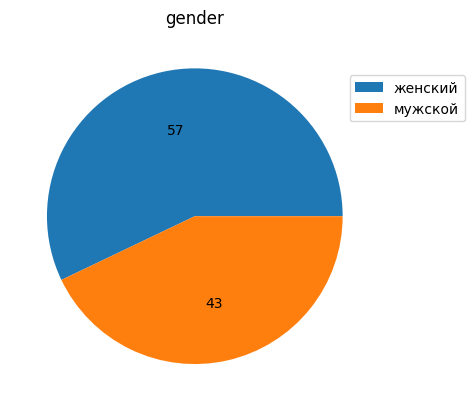

In [61]:
plt.pie(ds['gender'].value_counts().values, autopct='%.0f')
plt.title('gender')
plt.legend(labels=ds['gender'].value_counts().index, bbox_to_anchor=(0.9, 0.9))
plt.show()

**product_category**

In [62]:
ds['product_category'].value_counts()

,count
product_category,
Coffee,9948
Tea,7866
Bakery,3780
Drinking Chocolate,1955
Flavours,782
Coffee beans,217
Loose Tea,155
Branded,82
Packaged Chocolate,67


Построим столбчатую диаграмму распределения продуктовых категорий по количеству продаж

In [63]:
product_category_purchase = ds['product_category'].value_counts().sort_values(ascending=True)
product_category_purchase

,count
product_category,
Packaged Chocolate,67
Branded,82
Loose Tea,155
Coffee beans,217
Flavours,782
Drinking Chocolate,1955
Bakery,3780
Tea,7866
Coffee,9948


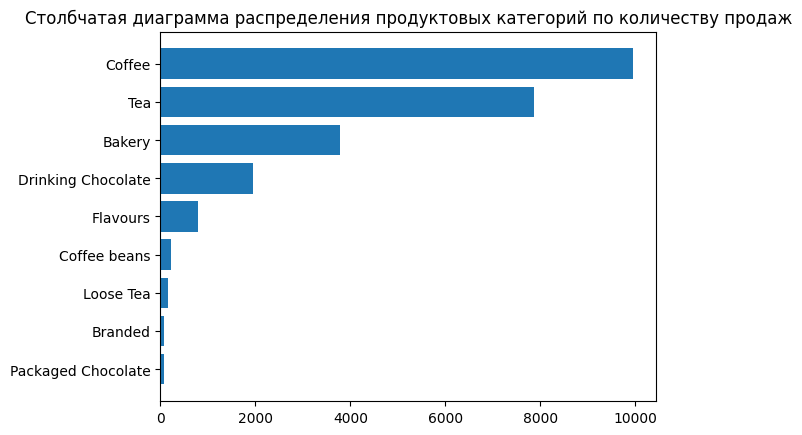

In [64]:
plt.barh(product_category_purchase.index, product_category_purchase.values)
plt.title('Столбчатая диаграмма распределения продуктовых категорий по количеству продаж')
plt.show()

In [65]:
# выделим 4 наиболее продаваемые категории
product_category_purchase_top_4 = ds['product_category'].value_counts().sort_values(ascending=False)[:4]
product_category_purchase_top_4

,count
product_category,
Coffee,9948
Tea,7866
Bakery,3780
Drinking Chocolate,1955


In [66]:
filter = ds['product_category'].apply(lambda x: x in product_category_purchase_top_4.index)
filter

,product_category
0,True
1,True
2,True
3,True
4,True
...,...
24847,True
24848,True
24849,True
24850,True


Создадим **ds_product_category_purchase_top_4** - датасет отфильтрованный по принадлежности продуктовой категории к списку Топ-4

In [67]:
ds_product_category_purchase_top_4 = ds[filter]
ds_product_category_purchase_top_4

,product_name,product_category,quantity,unit_price,total,store_city,sales_outlet_id,customer_id,age,gender
0,Traditional Blend Chai Rg,Tea,1,162.50,162.50,Санкт-Петербург,3,558,41,женский
1,Brazilian Lg,Coffee,2,227.50,455.00,Санкт-Петербург,3,781,33,женский
2,Serenity Green Tea Rg,Tea,2,162.50,325.00,Санкт-Петербург,3,788,29,женский
3,Our Old Time Diner Blend Rg,Coffee,2,162.50,325.00,Санкт-Петербург,3,683,25,женский
4,Jamaican Coffee River Sm,Coffee,1,159.25,159.25,Санкт-Петербург,3,99,57,мужской
...,...,...,...,...,...,...,...,...,...,...
24847,Cappuccino Lg,Coffee,1,276.25,276.25,Москва,8,8026,62,мужской
24848,Ouro Brasileiro shot,Coffee,1,136.50,136.50,Москва,8,8401,70,мужской
24849,Brazilian Sm,Coffee,2,143.00,286.00,Москва,8,8412,71,мужской
24850,Peppermint Rg,Tea,2,162.50,325.00,Москва,8,8030,30,женский


Составим круговую диаграмму продаж для топ-4 позиций

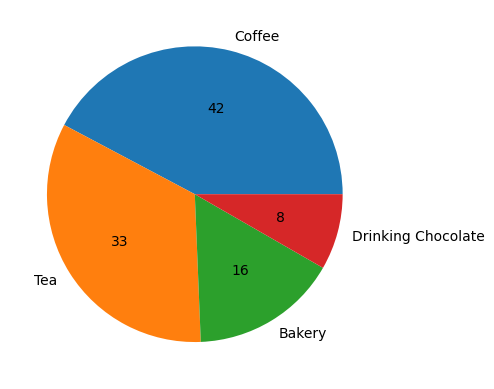

In [68]:
plt.pie(product_category_purchase_top_4, labels=product_category_purchase_top_4.index, autopct='%.0f')
plt.show()

Наиболее востребованные позиции: Coffee, Tea, Bakery, Drinking Chocolate. Кофе и чай (первое в 1.5 раза чаще второго) составляют 75% продаж.

**product_name**

Построим диаграмму распределения продаж товарных позиций (product_name)

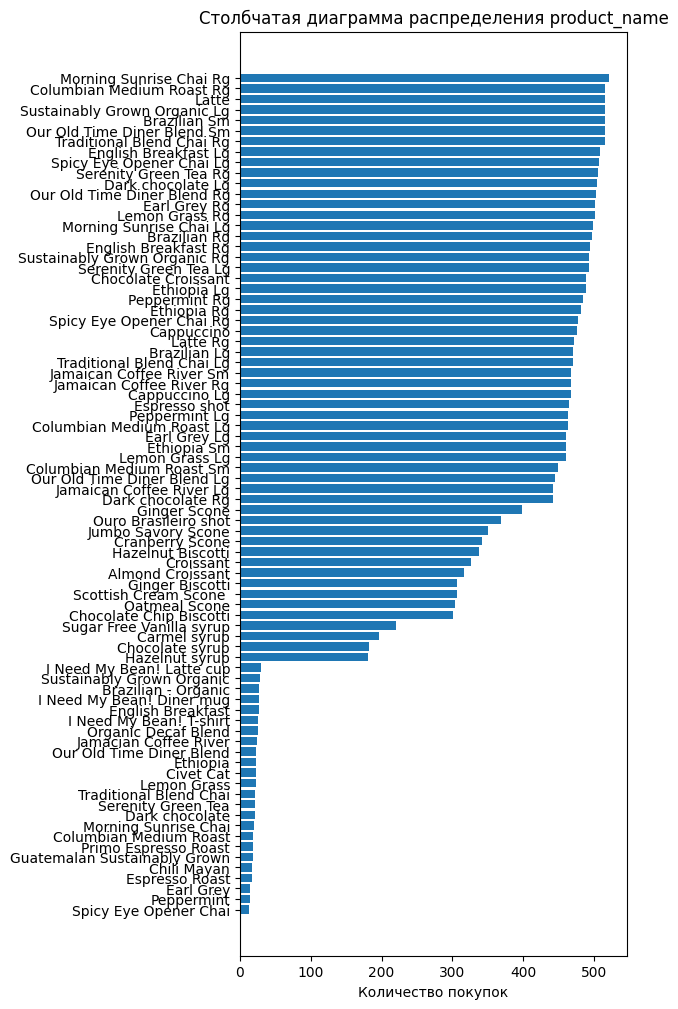

In [69]:
plt1 = plt.figure(figsize=(5,12))
data = ds.groupby('product_name')['product_name'].count().sort_values()
plt.barh(data.index, data.values)
plt.xlabel('Количество покупок')
plt.rc('ytick', labelsize= 5)
plt.title('Столбчатая диаграмма распределения product_name')
plt.show()

Основная масса покупок делается на товарных позициях собирающих от 400 покупок (таковых 40 позиций)

**customer_id**

In [70]:
ds['customer_id'].value_counts()

,count
customer_id,
3,31
8285,31
548,31
8341,29
8118,28
...,...
5589,1
359,1
5076,1


Построим гистограмму посещаемости

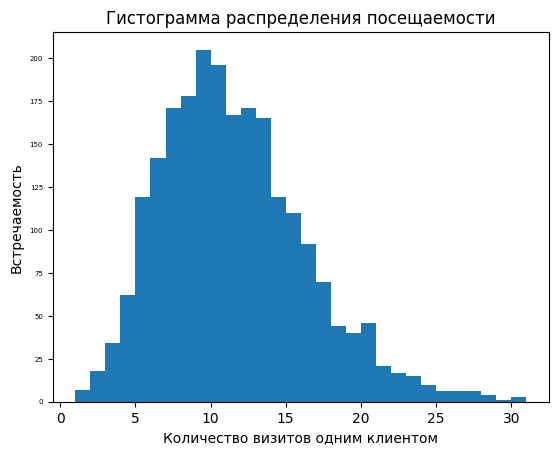

In [71]:
plt.hist(ds['customer_id'].value_counts().values, bins=30)
plt.xlabel('Количество визитов одним клиентом')
plt.ylabel('Встречаемость')
plt.title('Гистограмма распределения посещаемости')
plt.show()

Распределение похоже на нормальное. Можно утверждать, что среднее количество посещений на одного клиента равно верщине гистограммы и составляет примерно **10**. Примерно такая же величина получается делением общего количества записей (т.е. посещений) на количество уникальных клиентов. Очень мало посетителей на 1-2 раза, как и более 20. <br>
**Это свидетельствует о существовании вполне сложившейся аудитории со своим профилем предпочтений.**

### 4.7 Взаимосвязи категориальных признаков

**gender - store_city**

In [72]:
WF=pd.crosstab(ds['gender'], ds['store_city'], margins=True, normalize='columns')
WF

store_city,Москва,Санкт-Петербург,All
gender,,,
женский,0.570207,0.572326,0.57094
мужской,0.429793,0.427674,0.42906


Гендерная структура аудитории одинакова в региональном разрезе - женщин на 1/3 больше чем мужчин

**gender - product_category**

In [73]:
WF=pd.crosstab(ds['gender'], ds_product_category_purchase_top_4['product_category'], margins=True, normalize='columns')
WF

product_category,Bakery,Coffee,Drinking Chocolate,Tea,All
gender,,,,,
женский,0.568783,0.567752,0.584655,0.571955,0.570725
мужской,0.431217,0.432248,0.415345,0.428045,0.429275


Вкусовые предпочтения мужчин и женщин практически совпадают

**store_city - product_category**

In [74]:
WF=pd.crosstab(ds['store_city'], ds_product_category_purchase_top_4['product_category'], margins=True, normalize='index')
WF

product_category,Bakery,Coffee,Drinking Chocolate,Tea
store_city,,,,
Москва,0.164191,0.425627,0.079314,0.330868
Санкт-Петербург,0.153725,0.416546,0.089865,0.339865
All,0.160516,0.422438,0.083018,0.334027


Вкусовые предпочтения практически совпадают и по регионам

### 4.8 Описание количественных признаков

In [75]:
num_dtypes = dtypes[dtypes!='object']
num_columns = num_dtypes.index
ds_num = ds[num_columns]
ds_num

,quantity,unit_price,total,age
0,1,162.50,162.50,41
1,2,227.50,455.00,33
2,2,162.50,325.00,29
3,2,162.50,325.00,25
4,1,159.25,159.25,57
...,...,...,...,...
24847,1,276.25,276.25,62
24848,1,136.50,136.50,70
24849,2,143.00,286.00,71
24850,2,162.50,325.00,30


дискретные - age, quantity   <br>
непрерывные - unit_price, total

Расширим метод describe() с учетом интересующих нас доролнительных параметров - медиана, скошенность, эксцесс и p-значение теста д'Агастино на нормальность (при p < 0.05 распределение признака не относится к нормальным распределениям)

In [76]:
describe_ds_num = ds_num.describe()
describe_ds_num.loc['median'] = ds_num.median().tolist()
describe_ds_num.loc['skew'] = ds_num.skew().tolist()
describe_ds_num.loc['kurt'] = ds_num.kurtosis().tolist()
describe_ds_num.loc['norm'] = stats.normaltest(ds_num)[1].tolist()
print(describe_ds_num)

            quantity    unit_price         total           age
count   24852.000000  24852.000000  24852.000000  24852.000000
mean        1.435458    215.345534    299.613802     45.747545
std         0.527978    148.537146    230.478316     15.091661
min         1.000000     52.000000     52.000000     23.000000
25%         1.000000    162.500000    195.000000     32.000000
50%         1.000000    195.000000    243.750000     43.000000
75%         2.000000    243.750000    390.000000     59.000000
max         8.000000   2925.000000  23400.000000     74.000000
median      1.000000    195.000000    243.750000     43.000000
skew        0.660064      9.656031     42.789399      0.280799
kurt        0.028633    132.485590   4078.480587     -1.207187
norm        0.000000      0.000000      0.000000      0.000000


**quantity**

In [77]:
ds['quantity'].value_counts ()

,count
quantity,
1,14419
2,10054
3,373
4,5
8,1


Преобладают индивидуальные посетители. Их в 1.5 раза больше чем пар. Остальных исчезающе мало.

**age**

Построим гистограмму для признака age

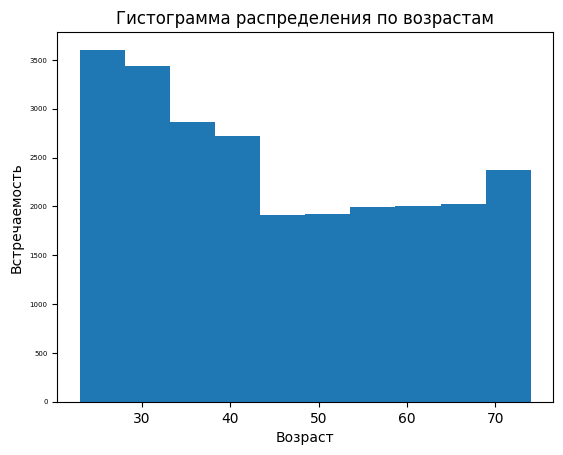

In [78]:
plt.hist(ds['age'])
plt.xlabel('Возраст')
plt.ylabel('Встречаемость')
plt.title('Гистограмма распределения по возрастам')
plt.show()

Средний возраст посетителей составляет 43 года, медианный - 45 лет. Распределение признака не является нормальным и имеет выраженный отрицательный эксцесс - средний возраст имеет меньшинство посетителей, основная же их масса представлена молодой (23-35) и возрастной (старше 60) публикой.

**unit_price**

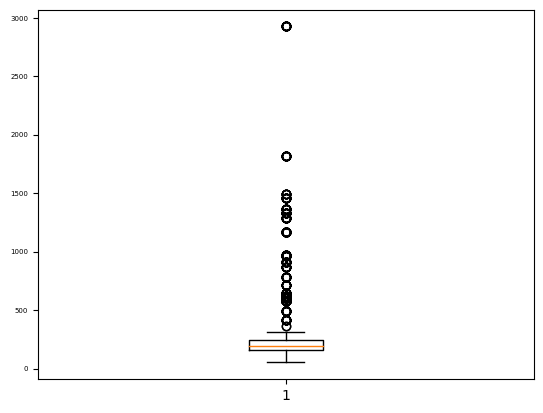

In [79]:
plt.boxplot(ds['unit_price'])
plt.show()

Основная масса покупок делается в отношении товара в ценовом диапазоне 50-350 руб.

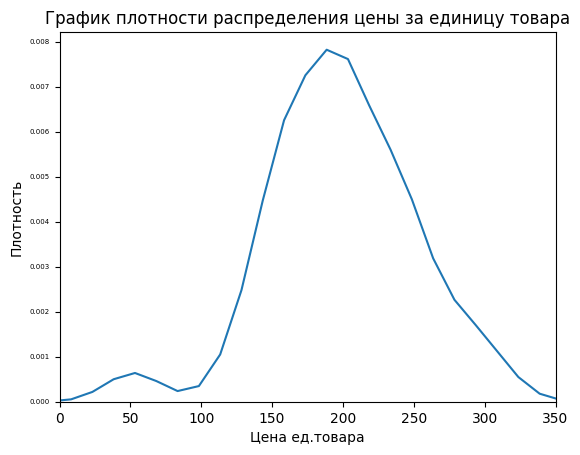

In [80]:
sns.kdeplot(ds['unit_price'])
plt.xlabel('Цена ед.товара')
plt.ylabel('Плотность')
plt.xlim(0, 350)
plt.title('График плотности распределения цены за единицу товара')
plt.show()

Наиболее ходовыми являются товары по цене 200<u><b>+</b></u>50 руб.

**total**

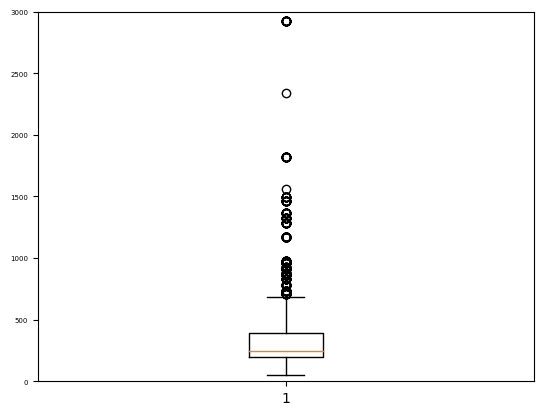

In [81]:
plt.boxplot(ds['total'])
plt.ylim(0, 3000)
plt.show()

Основная масса чеков имеет цену до 700 руб.

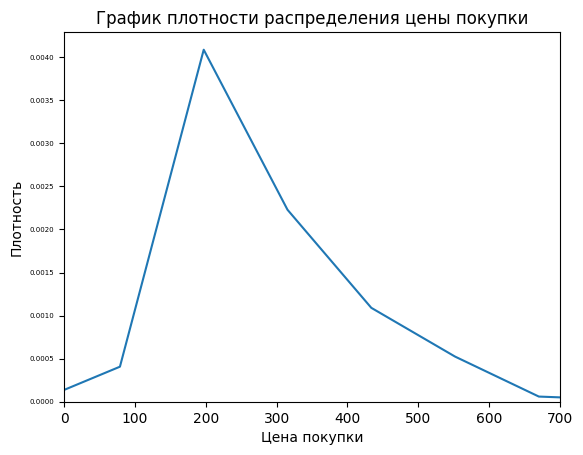

In [82]:
sns.kdeplot(ds['total'])
plt.xlabel('Цена покупки')
plt.ylabel('Плотность')
plt.xlim(0, 700)
plt.title('График плотности распределения цены покупки')
plt.show()

Наиболее распространенными являются чеки 150-400 руб. что соответствует среднему "полуторному" клиенту (средняя величина quantity = 1.43)<br>
Более точную оценку ситуации может дать диаграмма рассеяния и регрессионный анализ:

### 4.9 Взаимосвязи количественных признаков

**unit_price - total**

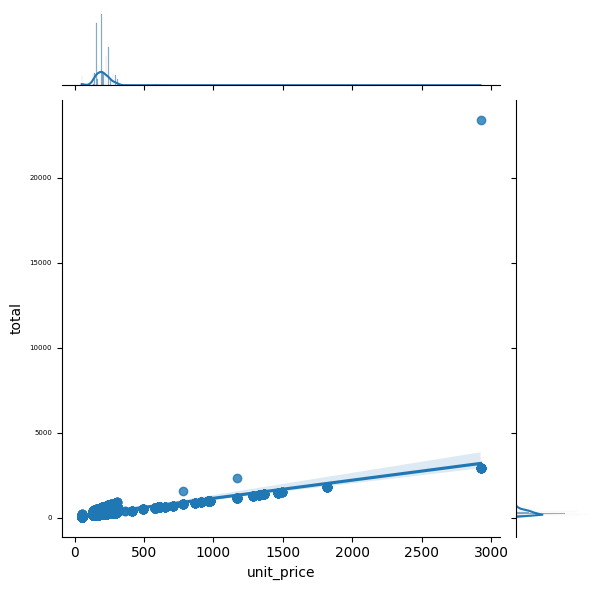

In [83]:
sns.jointplot(x='unit_price', y='total', data=ds, kind="reg")

In [84]:
LR = lm.LinearRegression()
print('Составим уравнение линейной регрессии величин unit_price и total:')
mod = LR.fit(ds[['unit_price']], ds[['total']])
r2 = mod.score(ds[['unit_price']], ds[['total']])
print(f'y = {round(float(mod.intercept_[0]), 2)} + x*{round(float(mod.coef_[0][0]), 5)}, коэфф.детерминации = {round(r2, 3)}')
print('x - unit_price, y - переменная total')

Составим уравнение линейной регрессии величин unit_price и total:
y = 69.76 + x*1.06738, коэфф.детерминации = 0.473
x - unit_price, y - переменная total


Регрессионное уравнение дает оценку коэффициента пропорциональности total и unit_price практически в 1. При этом свободный член регрессионного уравнения сопоставим с минимальной покупкой, что в рассматриваемом ценовом диапазоне существенно сказывается на результате и вероятнее всего указывает на различие потребительских предпочтений одиночек и пар.

**Построим попарную визуализацию**

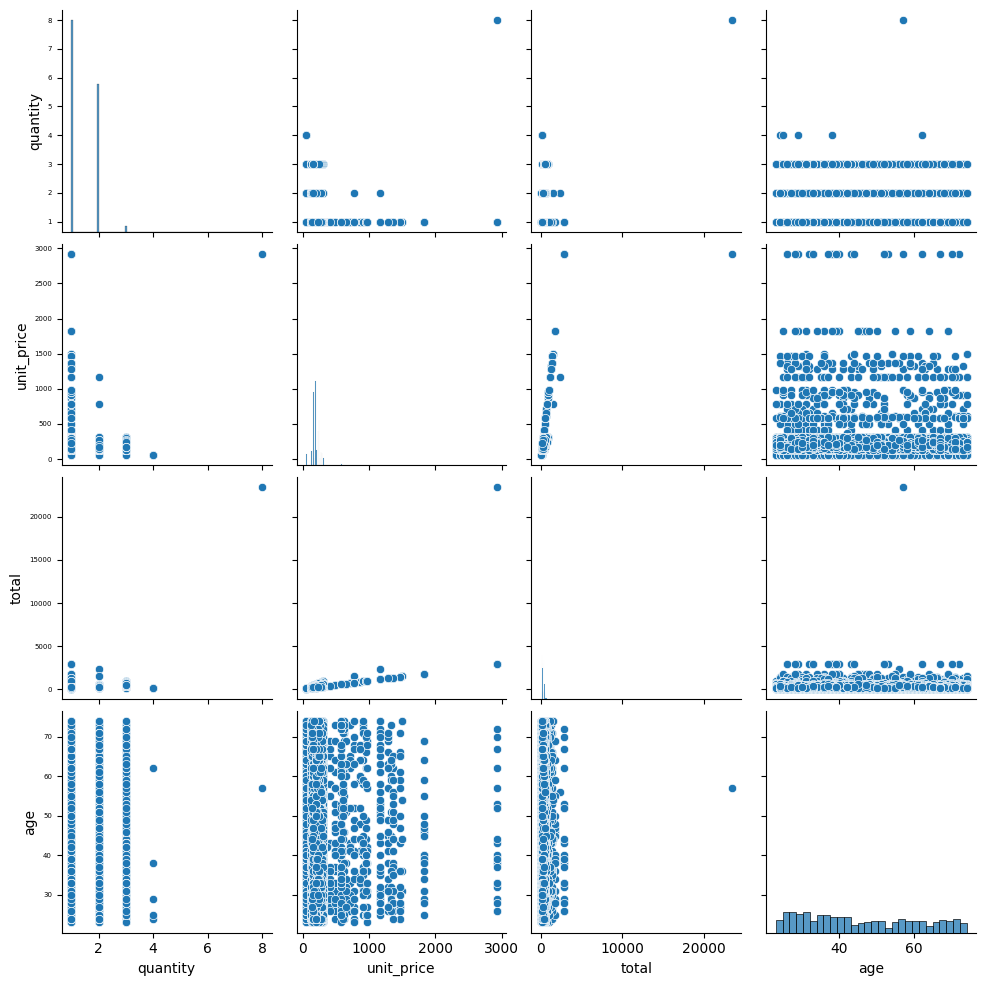

In [85]:
sns.pairplot(ds)

Иных связей кроме уже рассмотренной выше связи unit_price - total не обнаруживается.

### 4.10 Взаимосвязи номинальных и количественных признаков

**gender - age**

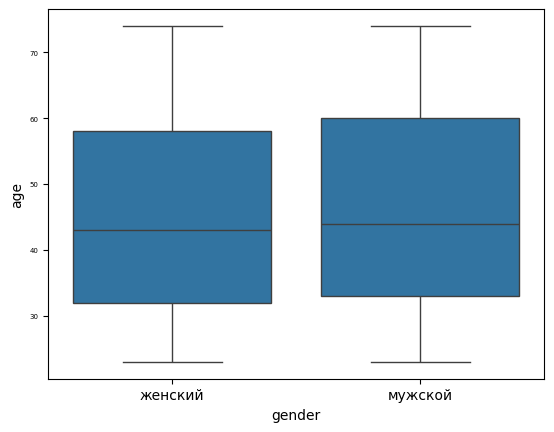

In [86]:
sns.boxplot(x='gender', y='age', data=ds)
plt.show()

Различия имеются, но на первый взгляд незначительные. Доверим решение статистическому анализу.<br>
Выборка age не соответсвуют нормальной генеральной совокупности, группы по признаку gender независимые и их чило = 2, поэтому выбираем критерий Манна-Уитни.

Гипотеза Н0: статистически значимые отличия в группах отсутствуют

In [87]:
ds1=ds[ds['gender']=='женский']['age']
ds2=ds[ds['gender']=='мужской']['age']
scipy.stats.mannwhitneyu(ds1, ds2)

MannwhitneyuResult(statistic=71891971.5, pvalue=1.9118319686502975e-11)

p-value << 0.05 (почти равно 0), соответственно мы должны отвергнуть гипотезу H0 и принять противоположное утверждение - о наличии статистически значимой связи между полом и возрастом аудитории - **медианный возраст и третий квартиль распределения возраста у мужчин несколько выше**.

**product_category - age**

In [88]:
data = ds_product_category_purchase_top_4

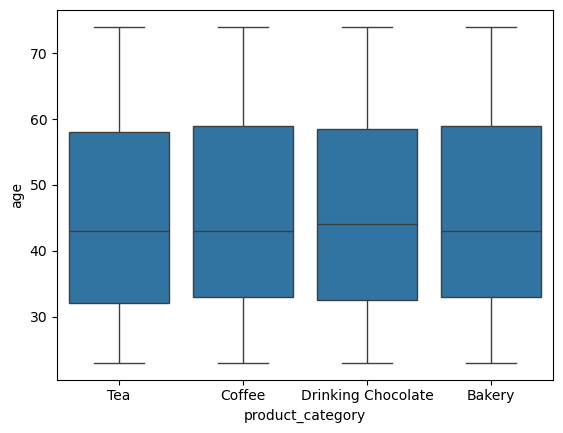

In [ ]:
sns.boxplot(x='product_category', y='age', data=data)
plt.show()

Гипотеза Н0: статистически значимые отличия в группах отсутствуют

Выборка age не соответсвуют нормальной генеральной совокупности, группы по признаку product_category независимые и их чило > 2, поэтому выбираем критерий Краскала-Уоллиса.

In [89]:
ds1=np.array(data[data['product_category']=='Coffee']['age'])
ds2=np.array(data[data['product_category']=='Tea']['age'])
ds3=np.array(data[data['product_category']=='Bakery']['age'])
ds4=np.array(data[data['product_category']=='Drinking Chocolate']['age'])
stats.mstats.kruskalwallis(ds1, ds2, ds3, ds4)

KruskalResult(statistic=8.030535365265235, pvalue=0.04538482911952981)

p-value < 0.05 (равно 0.045), соответственно формально мы должны отвергнуть гипотезу H0, однако оно настолько близко к границе, что при округлении даже дает 0.05, что побуждает признать случай пограничным и сохранить консервативную гипотезу H0. Тем более что осмотр ящиковой диаграммы не дает возможности ясно видеть взаимосвязь факторов. Хотя мы можем видеть например, что медианный возраст потребителей Drinking Chocolate совсем немного, но все же выше чем у остальных групп.<br>
**Как эксперт я решил остановиться на утверждении об отсутствии заметной связи между product_category и age.**

**sales_outlet_id - total**

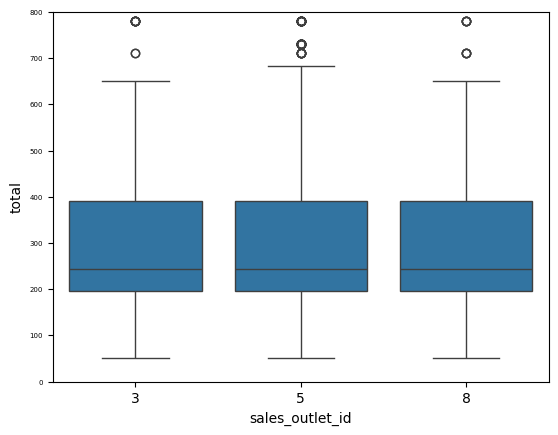

In [90]:
sns.boxplot(x='sales_outlet_id', y='total', data=ds)
plt.ylim(0, 800)
plt.show()

Можно видеть, что связь между sales_outlet_id и total отсутствует

**product_name - total**

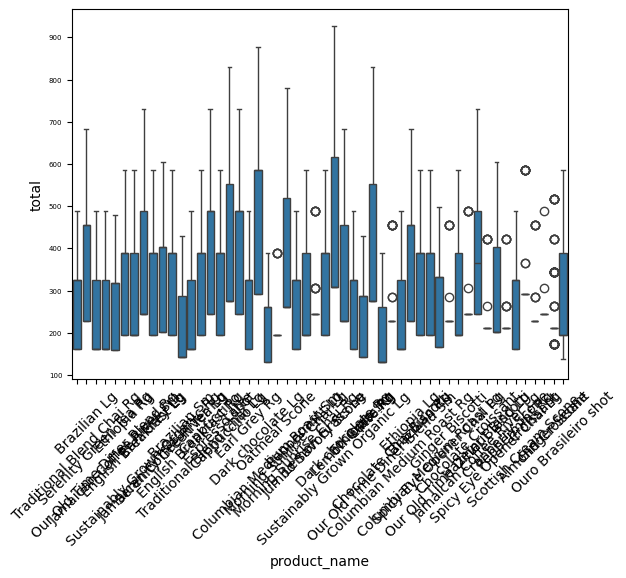

In [91]:
myplot = sns.boxplot(x='product_name', y='total', data=data)
plt.rc('xtick', labelsize= 5)
plt.setp(myplot.get_xticklabels(), rotation=45)
plt.show()

Цены имеют выраженный разброс

### 4.11 Финансовая деятельность компании

Влияние фактора quantity на выручку

In [92]:
ds.groupby('quantity')['total'].sum()

,total
quantity,
1,3344086.2
2,3872024.0
3,205452.0
4,1040.0
8,23400.0


Хотя одиночки встречаются в полтора раза чаще пар, пары дают на 16% больший доход - 3.9 млн. против 3.3 у одиночек.

Влияние фактора gender на выручку

In [93]:
ds.groupby('gender')['total'].sum().transform(lambda x: x/x.sum())

,total
gender,
женский,0.572959
мужской,0.427041


Женщины обеспечивают на 33% процента больше выручки, чем мужчины, в точном соответствии со своим количественным приемуществом

Влияние фактора age на выручку

In [94]:
ds.groupby('age')['total'].sum().transform(lambda x: x/x.sum())

,total
age,
23,0.007108
24,0.026089
25,0.026037
26,0.029583
27,0.026146
28,0.029815
29,0.027711
30,0.023463
31,0.027506


Построим столбчатую диаграмму распределения процентных долей выручки по годам возраста

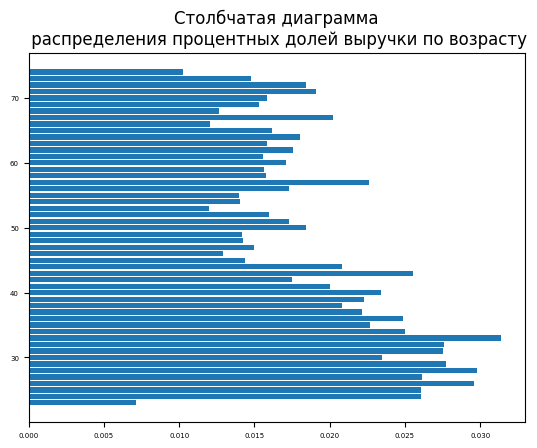

In [95]:
plt.barh(ds.groupby('age')['total'].sum().transform(lambda x: x/x.sum()).index, ds.groupby('age')['total'].sum().transform(lambda x: x/x.sum()).values)
plt.title('Столбчатая диаграмма\n распределения процентных долей выручки по возрасту')
plt.show()

Зададим разбиение на возрастные категории и найдем выручку для этих категорий

In [96]:
a = [23, 33, 43, 53, 63, 74]

In [97]:
age_group = []
revenue = []
def filter(i):
    return (ds['age']>a[i]) & (ds['age']<=a[i+1])
for j in range(0, len(a)-1, 1):
    print(str(a[j])+'-'+str(a[j+1]), int(ds[filter(j)]['total'].sum()))
    age_group.append(str(a[j])+'-'+str(a[j+1]))
    revenue.append(int(ds[filter(j)]['total'].sum()))

23-33 2050242
33-43 1669888
43-53 1155388
53-63 1230760
63-74 1286793


Построим столбчатую диаграмму распределения выручки по возрастным интервалам

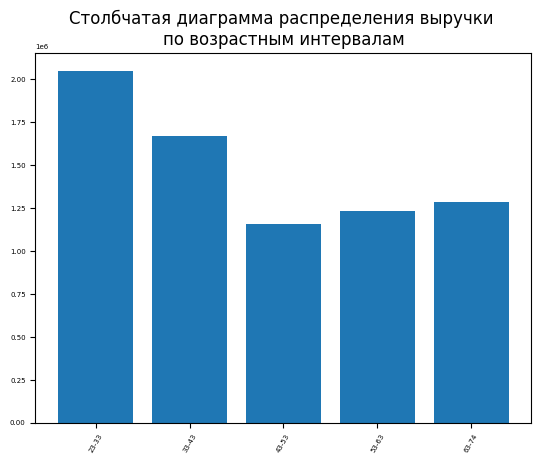

In [98]:
plt.bar(age_group, revenue)
plt.title('Столбчатая диаграмма распределения выручки \nпо возрастным интервалам')
plt.xticks(rotation = 60)
plt.show()

Мы видим, что молодежь (23-43) приносит почти половину дохода, другие возрастные группы дают оставшуюся половину приблизительно в равных долях

Рассмотрим распределение продаж по сети. <br>
Имеются три точки - 3, 5 и 8

In [99]:
gross = ds['total'].sum()
gross

7446002.2

Итак, полная выручка составляет около 7.5 млн. руб.

Выручка в разрезе точек

In [100]:
ds.groupby('sales_outlet_id')['total'].sum()

,total
sales_outlet_id,
3,2515132.10
5,2604307.55
8,2326562.55


Аудитория в разрезе точек

In [101]:
ds.groupby('sales_outlet_id')['quantity'].size()

,quantity
sales_outlet_id,
3,8593
5,8545
8,7714


Все точки дают примерно одинаковую выручку.<br>
С поправкой на размеры локальной аудитории, так же примерно равные, преимуществ ни у одной точки нет.

Распределение выручки по товарным категориям

In [102]:
ds.groupby('product_category')['total'].sum().sort_values(ascending=False).transform(lambda x: round(100 * x / x.sum(), 0))

,total
product_category,
Coffee,40.0
Tea,29.0
Bakery,12.0
Drinking Chocolate,11.0
Coffee beans,4.0
Branded,1.0
Loose Tea,1.0
Flavours,1.0
Packaged Chocolate,1.0


Финансово значимы только первые 2 позиции - Coffee и Tea

Выявим распределение выручки по товарным позициям в пределах 2 основных товарных категорий

Для Coffee

In [103]:
filter_Coffee = ds['product_category'] == 'Coffee'
filter_Coffee

,product_category
0,False
1,True
2,False
3,True
4,True
...,...
24847,True
24848,True
24849,True
24850,False


In [104]:
ds_Coffee = ds[filter_Coffee]
ds_Coffee

,product_name,product_category,quantity,unit_price,total,store_city,sales_outlet_id,customer_id,age,gender
1,Brazilian Lg,Coffee,2,227.50,455.00,Санкт-Петербург,3,781,33,женский
3,Our Old Time Diner Blend Rg,Coffee,2,162.50,325.00,Санкт-Петербург,3,683,25,женский
4,Jamaican Coffee River Sm,Coffee,1,159.25,159.25,Санкт-Петербург,3,99,57,мужской
5,Ethiopia Rg,Coffee,1,195.00,195.00,Санкт-Петербург,3,664,28,женский
10,Jamaican Coffee River Rg,Coffee,2,201.50,403.00,Санкт-Петербург,3,35,68,мужской
...,...,...,...,...,...,...,...,...,...,...
24845,Ouro Brasileiro shot,Coffee,1,136.50,136.50,Москва,8,8107,29,женский
24846,Ouro Brasileiro shot,Coffee,2,195.00,390.00,Москва,8,8431,58,мужской
24847,Cappuccino Lg,Coffee,1,276.25,276.25,Москва,8,8026,62,мужской
24848,Ouro Brasileiro shot,Coffee,1,136.50,136.50,Москва,8,8401,70,мужской


In [105]:
ds_Coffee.groupby('product_name')['total'].sum().head(50).sort_values().transform(lambda x: round(100 * x / x.sum(), 1))#.cumsum()

,total
product_name,
Columbian Medium Roast Sm,3.0
Ouro Brasileiro shot,3.3
Our Old Time Diner Blend Sm,3.4
Ethiopia Sm,3.4
Brazilian Sm,3.8
Jamaican Coffee River Sm,3.9
Our Old Time Diner Blend Rg,4.2
Columbian Medium Roast Rg,4.3
Our Old Time Diner Blend Lg,4.4


Выберем верхние 6 сортов кофе со вкладом в выручку категории Coffee до 4%

In [106]:
Coffee_2change = ds_Coffee.groupby('product_name')['total'].sum().head(50).sort_values().transform(lambda x: round(100 * x / x.sum(), 1))[:6]
Coffee_2change.index.to_list()

['Columbian Medium Roast Sm',
 'Ouro Brasileiro shot',
 'Our Old Time Diner Blend Sm',
 'Ethiopia Sm',
 'Brazilian Sm',
 'Jamaican Coffee River Sm']

Для Tea

In [107]:
filter_Tea = ds['product_category'] == 'Tea'
ds_Tea = ds[filter_Tea]
ds_Tea

,product_name,product_category,quantity,unit_price,total,store_city,sales_outlet_id,customer_id,age,gender
0,Traditional Blend Chai Rg,Tea,1,162.5,162.5,Санкт-Петербург,3,558,41,женский
2,Serenity Green Tea Rg,Tea,2,162.5,325.0,Санкт-Петербург,3,788,29,женский
6,English Breakfast Lg,Tea,2,195.0,390.0,Санкт-Петербург,3,316,72,женский
8,Earl Grey Lg,Tea,2,195.0,390.0,Санкт-Петербург,3,370,65,женский
9,English Breakfast Lg,Tea,2,195.0,390.0,Санкт-Петербург,3,180,44,мужской
...,...,...,...,...,...,...,...,...,...,...
24829,Spicy Eye Opener Chai Lg,Tea,1,201.5,201.5,Москва,8,8101,50,женский
24830,English Breakfast Rg,Tea,2,162.5,325.0,Москва,8,8496,47,женский
24833,Serenity Green Tea Lg,Tea,2,195.0,390.0,Москва,8,8486,24,мужской
24836,Peppermint Lg,Tea,2,195.0,390.0,Москва,8,8155,37,женский


In [108]:
ds_Tea.groupby('product_name')['total'].sum().head(50).sort_values().transform(lambda x: round(100 * x / x.sum(), 1))#.cumsum()

,total
product_name,
Peppermint Rg,5.5
Spicy Eye Opener Chai Rg,5.5
English Breakfast Rg,5.6
Serenity Green Tea Rg,5.7
Lemon Grass Rg,5.8
Earl Grey Rg,5.9
Traditional Blend Chai Rg,5.9
Morning Sunrise Chai Rg,5.9
Peppermint Lg,6.2


Выберем верхние 4 сорта чая со вкладом в выручку категории Tea до 5.7% включительно

In [109]:
Tea_2change = ds_Tea.groupby('product_name')['total'].sum().head(50).sort_values().transform(lambda x: round(100 * x / x.sum(), 1))[:4]
Tea_2change.index.to_list()

['Peppermint Rg',
 'Spicy Eye Opener Chai Rg',
 'English Breakfast Rg',
 'Serenity Green Tea Rg']

Выбранные сорта кофе и чая можно рекомендовать к замене на другие сорта для целей маркетингового эсперимента

## 5. Выводы и решения

### 5.1 Датасет

1. Датасет состоит из 24909 наблюдений по 6 признакам.
2. В Датасете представлены данные видов object, int64 и float64.
3. Найдено 57 полных дубликатов и они удалены. Количество наблюдений в обновленном датасете составило 24852.
4. Пропущенные значения имеются только в столбце gender, они заполнены рандомно в соответствии со свойствами признака.
5. Очищенный Датасет состоит из 24852 наблюдений по 10 признакам с данными видов - object, int64 и float64
6. Признаки разделены на: 6 строковых (object) - product_name, product_category, store_city, sales_outlet_id, customer_id, gender, 2 целочисленных (int64) - quantity, age и 2 вещественных (float64) - unit_price, total
7. С точки зрения общепринятой статистической классификации признаки можно разделить на три группы: категориальные - product_name, product_category, store_city, sales_outlet_id, customer_id, gender; дискретные количественные - age, quantity; непрерывные количественные - unit_price, total. Порядковые признаки отстутствуют.

### 5.2 Аудитория

Распределение посещаемости похоже на нормальное. Можно утверждать, что среднее количество посещений на одного клиента равно верщине гистограммы распределения посещаемости и составляет примерно 10. Примерно такая же величина получается делением общего количества записей (посещений) на количество уникальных клиентов. Очень мало посетителей на 1-2 раза, как и более 20. Это свидетельствует о существовании вполне сложившейся аудитории со своим профилем предпочтений.<br>
Вкусовые предпочтения мужчин и женщин практически совпадают, как в целом, так и по регионам<br>
Преобладают индивидуальные посетители. Их в 1.5 раза больше чем пар. Остальных исчезающе мало.<br>
Средний возраст посетителей составляет 43 года, медианный - 45 лет. Распределение признака не является нормальным и имеет выраженный отрицательный эксцесс - средний возраст имеет меньшинство посетителей, основная же их масса представлена молодой (23-35) и возрастной (старше 60) публикой.<br>
Аудитория характеризуется преимущественной (на 1/3) численностью женщин как в целом по сети, так и в региональном разрезе.<br>
Мы можем видеть, что в СПб расположен один пункт (sales_outlet_id 3), а в Москве - два пункта (5 и 8), причем аудитории московских пунктов не пересекаются.<br>
**Целевой аудиторией можно считать посетителей в возррасте 23-43 лет.** <br>Тогда как вычленение категорий "одиночный постетитель - пара" или по половому признаку не дает выраженного профиля т.к. преобладание не является значительным.

### 5.3 Потребительские предпочтения

1. Наиболее востребованные позиции: Coffee, Tea, Bakery, Drinking Chocolate. Кофе и чай (первое в 1.5 раза чаще второго) составляют 75% продаж.
2. Основная масса покупок делается на товарных позициях собирающих от 400 покупок (таковых 40 позиций) и в отношении товара в ценовом диапазоне 50-350 руб., при этом наиболее ходовыми являются товары по цене 200<u>+</u>50 руб.
3. Основная масса чеков имеет цену до 700 руб., при этом наиболее распространенными являются чеки 150-400 руб. что соответствует среднему "полуторному" клиенту (средняя величина quantity = 1.43)

### 5.4 Финансовые аспекты деятельности

1. Полная выручка составляет около 7.5 млн. руб
2. Хотя одиночки встречаются в полтора раза чаще пар, пары дают на 16% больший доход - 3.9 млн. против 3.3 у одиночек.
3. Женщины обеспечивают на 33% процента больше выручки, чем мужчины, в точном соответствии со своим количественным приемуществом
4. Молодежь (возраст 23-43 г) приносит почти половину дохода, другие возрастные группы дают оставшуюся половину приблизительно в равных долях
5. Все точки дают примерно одинаковую выручку. С поправкой на размеры локальной аудитории, так же примерно равные, преимуществ ни у одной точки нет.
5. Распределение выручки по товарным категориям: финансово значимы только первые 2 позиции - Coffee (40% выручки) и Tea (30%)
6. Распределение выручки по товарным позициям (product_name) не имеет ярко выраженных преимуществ у каки-либо из них.
Тем не менее можно выбрать 6 нижних позиций по разеру выручки для кофе и 4 для чая, совокупный вклад которых в свои товарные категории приблизительно составляет 20%.
**Для кофе это Columbian Medium Roast Sm, Ouro Brasileiro shot, Our Old Time Diner Blend Sm, Ethiopia Sm, Brazilian Sm, Jamaican Coffee River Sm.** - вклад каждой из этих позиций не более 4% от совокупной выручки по категории Coffee. Назовем этот список условно **Кофе-на-замену**.<br>
**Для чая это Peppermint Rg, Spicy Eye Opener Chai Rg, English Breakfast Rg, Serenity Green Tea Rg.** - вклад каждой из этих позиций не более 5.7% от совокупной выручки по категории Tea. Назовем этот список условно **Чай-на-замену**.

### 5.5 Выводы и рекомендации

Очевидно, что бизнес обладает хорошо выстроенной структурой - практически все его значимые показатели не имеют резких перепадов и таким образом находятся в состоянии равновесия, с позиций Общей теории систем наиболее эффективном из всех рабочих состояний.<br>
Это позволяет рекомендовать расширение бизнеса путем, в частности, создания одной дополнительной точки в Москве в течение 2 месяцев и одной в Санкт-Петербурге в течение последующих 2 месяцев при условии, что первая точка будет развиваться успешно в соответствии с бизнес-планом. <br>Так же можно применительно к этим новым точкам либо просто сократить ассортимент перечисленный в списках Кофе-на-замену и Чай-на-замену, что сократит накладные расходы, либо заменить эти позиции на новые, что более рискованно, но представляется более интересным в аспекте развития бизнеса.<br>
Остальные товарные категории (Bakery, Drinking Chocolate, Coffee beans, Branded, Loose Tea, Flavours, Packaged Chocolate) предлагается сохранить для поддержания необходимой товарной экосистемы.<br>
Для повышения комфорта молодежной составляющей аудитории (целевой) можно рекомедовать насыщение пространства средствами коммуникаций (WiFi, бесплатное пользование планшетами компании, доступ к внутренней вебкамере или смс-сервис с информацией о заполненности зала и т.п.)